# Annotazione finale di context relevance: accordo e valutazione del retrieval

Passi dell'analisi:

1. caricamento delle annotazioni;
2. **accordo** tra le annotatrici sul questionario comune;
3. etichette finali (gold) dei 110 item;
4. **rilevanza media del top-4** e **nDCG@4** delle quattro configurazioni;
5. **embedder × reranker**;
6. **pattern per etichetta**.

I calcoli sono quelli di `evaluate_retrieval.py` (che riusa le statistiche dell'analisi del pilot)
e i grafici quelli di `plot_results.py`; il notebook li richiama e mostra i risultati.
Eseguire con **Run All**.

In [21]:
import importlib
import sys
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import Image, display

# Cartella del notebook (o radice del progetto, se il kernel parte da lì).
HERE = Path.cwd() if (Path.cwd() / "evaluate_retrieval.py").is_file() \
    else Path.cwd() / "Qualtrics" / "retrieval_internal_annotation_final"
sys.path.insert(0, str(HERE))

import evaluate_retrieval as er
import plot_results as pr

# Ricarica i moduli: se gli script sono stati modificati, il kernel usa la versione aggiornata.
er = importlib.reload(er)
pr = importlib.reload(pr)

pd.set_option("display.float_format", lambda v: f"{v:.3f}")
rng = np.random.default_rng(er.SEED)

## 1. Caricamento delle annotazioni

- **Comune** (`pilot_harmonized.csv`): 29 item giudicati da marem, arianna e marta, più la riga
  `Harmonized` compilata dopo la discussione.
- **Individuali**: 27 item per annotatrice, giudicati da lei sola.

Scala: 0 = not relevant, 1 = partially relevant, 2 = relevant. La conversione dai codici Qualtrics
usa il testo delle scelte nel QSF, e per ogni colonna si verifica che il QID coincida con la mappa.

### Codice di lettura delle annotazioni

Le funzioni sotto sono quelle di `evaluate_retrieval.py`, mostrate così come sono (non una copia):

- `read_export`: legge l'export CSV di Qualtrics, anche se risalvato da Excel con `;`;
- `choice_scale`: dal QSF, associa a ogni domanda il codice Qualtrics (1/2/3) e il testo della scelta
  ("0 - Not relevant", …) al valore 0/1/2;
- `load_survey`: per un questionario, verifica che ogni colonna dell'export abbia il QID previsto dalla
  mappa e restituisce una tabella *annotatrice × item* con valori 0/1/2;
- `load_annotations`: carica il comune (`pilot_harmonized.csv`) e i tre questionari individuali;
- `load_items`: unisce le quattro mappe domanda → (etichetta EDOS, chunk, configurazioni e rank).

In [22]:
import inspect
from IPython.display import Markdown

functions = [er.read_export, er.choice_scale, er.load_survey, er.load_annotations, er.load_items]
display(Markdown("```python\n" + "\n\n".join(inspect.getsource(f) for f in functions) + "```"))

```python
def read_export(path: Path) -> pd.DataFrame:
    """Qualtrics CSV export (original or re-saved by Excel with ';')."""
    return pd.read_csv(path, sep=None, engine="python", dtype=str, keep_default_na=False, encoding="utf-8-sig")


def choice_scale(qsf_path: Path) -> dict[str, dict[str, int]]:
    """Per question: choice code and choice text -> 0/1/2, from the QSF choice texts."""
    survey = json.loads(qsf_path.read_text(encoding="utf-8"))
    scales = {}
    for element in survey["SurveyElements"]:
        payload = element["Payload"] if element["Element"] == "SQ" else None
        if not payload or "-chunk_" not in payload.get("DataExportTag", ""):
            continue
        scale = {}
        for code, choice in payload["Choices"].items():
            value = int(re.match(r"\s*(\d)", choice["Display"]).group(1))
            scale[code] = value
            scale[choice["Display"].strip()] = value
        scales[payload["DataExportTag"]] = scale
    return scales


def load_survey(export_path: Path, survey: str) -> pd.DataFrame:
    """Rows: respondents (by name); columns: question_id; values 0/1/2 or NaN."""
    mapping = pd.read_csv(HERE / f"{survey}_question_map.csv", dtype=str, keep_default_na=False)
    scales = choice_scale(HERE / f"{survey}.qsf")
    raw = read_export(export_path)
    import_ids, responses = raw.iloc[1], raw.iloc[2:]
    for item in mapping.itertuples():
        if json.loads(import_ids[item.data_export_tag])["ImportId"] != item.qualtrics_question_id:
            raise ValueError(f"{export_path.name}: {item.data_export_tag} has a QID different from {survey} map.")
    names = responses["Annotator"].tolist() if survey == "comune" else [survey] * len(responses)
    table = {}
    for item in mapping.itertuples():
        scale = scales[item.data_export_tag]
        table[item.question_id] = [scale[v.strip()] if v.strip() else np.nan for v in responses[item.data_export_tag]]
    frame = pd.DataFrame(table, index=names)
    if frame.index.duplicated().any():
        raise ValueError(f"{export_path.name}: duplicated respondents {frame.index.tolist()}")
    return frame


def load_annotations(annotations: Path = ANNOTATIONS):
    """Common survey (3 annotators + Harmonized row) and the three private surveys."""
    common = load_survey(annotations / "pilot_harmonized.csv", "comune")
    private = {name: load_survey(next(annotations.glob(f"*context_relevance_{name}_*.csv")), name)
               for name in ANNOTATORS}
    return common, private


def load_items() -> pd.DataFrame:
    frames = []
    for survey in ("comune", *ANNOTATORS):
        mapping = pd.read_csv(HERE / f"{survey}_question_map.csv", dtype=str, keep_default_na=False)
        mapping["survey"] = survey
        frames.append(mapping)
    items = pd.concat(frames, ignore_index=True).set_index("question_id")
    if items.index.duplicated().any() or items.duplicated(["edos_label", "chunk_id"]).any():
        raise ValueError("Question maps overlap: each (label, chunk) item must appear once.")
    return items
```

**Da cosa si parte e cosa si ottiene.** Dopo il caricamento, una cella mostra le prime tre domande
dell'export grezzo del comune: intestazione = nomi delle colonne Qualtrics; riga 0 = testo della domanda;
riga 1 = ImportId con il QID (controllato contro la mappa); poi una riga per annotatrice e la riga
`Harmonized` (vuota dove l'item non è stato discusso). Sotto, le stesse risposte dopo la conversione in 0/1/2.

In [23]:
items = er.load_items()
common, private = er.load_annotations()
judges = common.loc[list(er.ANNOTATORS)]   # 3 annotatrici x 29 item
harmonized = common.loc["Harmonized"]

print("Item per questionario:", items.survey.value_counts().to_dict())
judges.apply(lambda row: row.value_counts().reindex(er.LEVELS, fill_value=0), axis=1)

Item per questionario: {'comune': 29, 'marem': 27, 'arianna': 27, 'marta': 27}


,0,1,2
marem,11,8,10
arianna,10,8,11
marta,13,10,6


In [24]:
raw = er.read_export(er.ANNOTATIONS / "pilot_harmonized.csv")
answer_columns = [c for c in raw.columns if "-chunk_" in c][:3]
print("Export grezzo (prime 3 domande):")
display(raw[["Annotator", *answer_columns]].map(lambda v: v if len(v) <= 40 else v[:40] + "…"))
print("Dopo load_survey (valori 0/1/2, stesse 3 domande):")
display(common[answer_columns])

Export grezzo (prime 3 domande):


,Annotator,Q4dc5f2ecb14a8bb7-chunk_1af1d271fbb3edc000bc0d44,Q363a0511ec4837f6-chunk_303528c2ac040ddcbe3f2cd1,Qf545b1b1b8d98f8f-chunk_81ac68577124450a8fd9db9b
0,AnnotatriceSeleziona il tuo nome.,EDOS Label1.1 threats of harm – Expressi…,EDOS Label1.1 threats of harm – Expressi…,EDOS Label1.1 threats of harm – Expressi…
1,"{""ImportId"":""QID31""}","{""ImportId"":""QID32""}","{""ImportId"":""QID34""}","{""ImportId"":""QID36""}"
2,marem,2 - Relevant,2 - Relevant,1 - Partially relevant
3,arianna,2 - Relevant,2 - Relevant,1 - Partially relevant
4,marta,0 - Not relevant,1 - Partially relevant,2 - Relevant
5,Harmonized,1 - Partially relevant,,


Dopo load_survey (valori 0/1/2, stesse 3 domande):


,Q4dc5f2ecb14a8bb7-chunk_1af1d271fbb3edc000bc0d44,Q363a0511ec4837f6-chunk_303528c2ac040ddcbe3f2cd1,Qf545b1b1b8d98f8f-chunk_81ac68577124450a8fd9db9b
marem,2,2.000,1.000
arianna,2,2.000,1.000
marta,0,1.000,2.000
Harmonized,1,NaN,NaN


## 2. Accordo sul comune

**Prima della discussione.** Alpha di Krippendorff ordinale con IC 95% (bootstrap degli item) e
accordo esatto, con la funzione `agreement_summary` del pilot. Lettura (Krippendorff, 2004):
α ≥ 0,800 affidabile, α ≥ 0,667 minimo per conclusioni provvisorie.

In [25]:
agreement = er.common_agreement(judges, harmonized, rng)
rows = {"tutte e tre": agreement["all_three"],
        **{pair.replace("-", " – "): stats for pair, stats in agreement["pairwise"].items()}}
table = pd.DataFrame(rows).T[["alpha_ordinal", "alpha_ci_low", "alpha_ci_high", "pairwise_exact_agreement"]]
table.loc["tutte e tre", "pairwise_exact_agreement"] = agreement["all_three_identical"]
table.columns = ["α ordinale", "IC 95% basso", "IC 95% alto", "accordo esatto"]
table

,α ordinale,IC 95% basso,IC 95% alto,accordo esatto
tutte e tre,0.234,-0.006,0.454,0.241
marem – arianna,0.064,-0.334,0.435,0.448
marem – marta,0.350,0.001,0.625,0.414
arianna – marta,0.314,-0.061,0.609,0.448


Per le coppie, *accordo esatto* è la quota di item con lo stesso giudizio; per *tutte e tre*, la quota
di item su cui coincidono tutte.

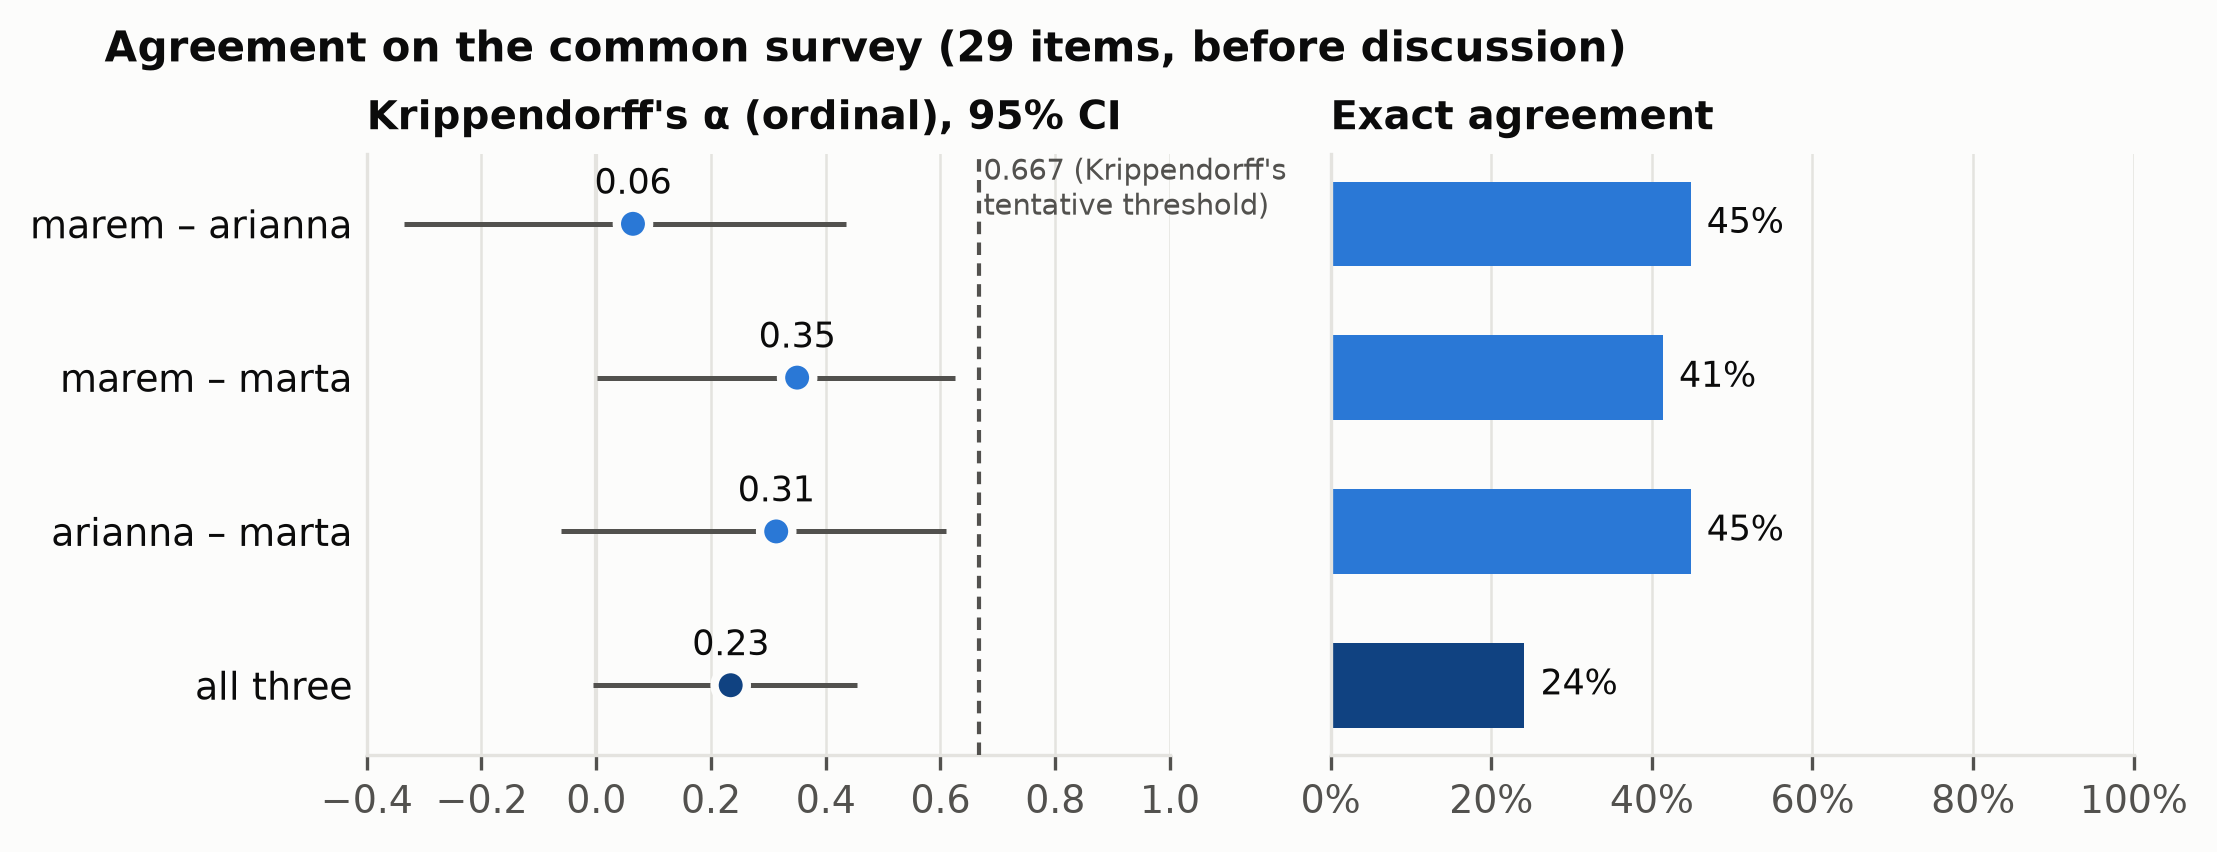

In [26]:
pr.figure_agreement(agreement)
display(Image(pr.FIGURES / "6_agreement_common.png", width=850))

**Dopo la discussione.** I 29 item del comune si dividono in tre gruppi, a seconda di quanto
distano tra loro i tre giudizi (massimo − minimo):

- **0**: tutte e tre uguali → nessuna discussione, l'etichetta finale è quel valore;
- **1**: due uguali e una a un punto di distanza (es. 2, 2, 1) → nessuna discussione, l'etichetta finale
  è la mediana, cioè il valore della maggioranza;
- **2**: un 0 e un 2 (disaccordo massimo) → discussi insieme, l'etichetta finale è il valore armonizzato.

In [27]:
spread = (judges.max(axis=0) - judges.min(axis=0)).astype(int)
groups = pd.DataFrame({
    "item": spread.value_counts().sort_index(),
    "discussi": spread[harmonized.notna()].value_counts().reindex(spread.value_counts().sort_index().index, fill_value=0),
})
groups.index = ["0 · tutte uguali", "1 · disaccordo di un punto", "2 · un 0 e un 2"][:len(groups)]
groups

,item,discussi
0 · tutte uguali,7,0
1 · disaccordo di un punto,12,0
2 · un 0 e un 2,10,10


Per i 10 item discussi: i giudizi iniziali, la decisione presa insieme e quanto ogni annotatrice era
vicina a essa.

In [28]:
discussed = harmonized.notna()
discussion = judges.loc[:, discussed].T.astype(int)
discussion["armonizzato"] = harmonized[discussed].astype(int)
items.loc[discussion.index, ["edos_label"]].join(discussion)

,edos_label,marem,arianna,marta,armonizzato
Q4dc5f2ecb14a8bb7-chunk_1af1d271fbb3edc000bc0d44,1.1 threats of harm,2,2,0,1
Qeb36ba85a34172b0-chunk_93cd474ca73aee9e9a6ff841,1.2 incitement and encouragement of harm,0,2,1,1
Qa75a785ebe8b3005-chunk_348b1aa54150426fda5b3f16,2.1 descriptive attacks,2,1,0,1
Qc0a791c4dc29f096-chunk_470edb697d0c77b54eed867e,"3.1 casual use of gendered slurs, profanities,...",0,2,1,2
Q113e15ad31cc81fc-chunk_ca4bfb14eec60de82c407049,"3.1 casual use of gendered slurs, profanities,...",0,2,2,1
Q4769b6aeddac27e7-chunk_448daa7158663571f185ffbb,3.3 backhanded gendered compliments,0,2,1,1
Qf3ab511f59bc54d3-chunk_5437e27e98d60e6f2a587419,3.3 backhanded gendered compliments,0,2,0,1
Q43522782264965f3-chunk_1596ed71ffde7043811e3e00,3.3 backhanded gendered compliments,2,0,2,2
Q4eebc5e654de25c7-chunk_1500d420821ba665489c1207,4.2 supporting systemic discrimination against...,2,0,1,0
Qa49d39b9e8879d7a-chunk_4a02d907b0c74dae2be00ee0,4.2 supporting systemic discrimination against...,2,0,2,2


In [29]:
pd.DataFrame(agreement["vs_harmonized_on_discussed_items"]).T.rename(columns={
    "exact_agreement": "accordo esatto con l'armonizzato",
    "mean_absolute_difference": "distanza media (0–2)"})

,accordo esatto con l'armonizzato,distanza media (0–2)
marem,0.200,1.000
arianna,0.300,0.900
marta,0.400,0.600


**Perché qui non c'è l'α.** Questi 10 item sono stati scelti *proprio perché* c'era un disaccordo
massimo: per costruzione, su ognuno almeno un'annotatrice era lontana dalla decisione finale. Un α
calcolato solo su di essi risulterebbe basso per come sono stati selezionati, non per la qualità delle
annotatrici; e su 10 item sarebbe comunque molto instabile. Per questo si riportano solo accordo esatto
e distanza media, a scopo descrittivo. La misura di affidabilità è l'α sui 29 item **prima** della
discussione (sopra).

**Accordo finale (dopo la discussione).** Si ricalcola l'accordo assegnando a tutte e tre le annotatrici
il valore armonizzato sui 10 item discussi; gli altri 19 restano con i giudizi originali (7 unanimi e
12 con un disaccordo di un punto).

Va letto come **consenso finale** raggiunto, non come affidabilità indipendente: è più alto per
costruzione, perché i disaccordi più forti sono stati risolti insieme. Nel paper vanno riportati
entrambi: l'α prima della discussione (affidabilità) e quello dopo (consenso finale).

In [30]:
def agreement_rows(block):
    rows = {"tutte e tre": block["all_three"],
            **{pair.replace("-", " – "): stats for pair, stats in block["pairwise"].items()}}
    frame = pd.DataFrame(rows).T[["alpha_ordinal", "alpha_ci_low", "alpha_ci_high", "pairwise_exact_agreement"]]
    frame.loc["tutte e tre", "pairwise_exact_agreement"] = block["all_three_identical"]
    return frame

final = agreement["after_discussion"]
comparison = pd.concat({"prima della discussione": agreement_rows(agreement),
                        "dopo la discussione": agreement_rows(final)}, axis=1)
comparison.columns = pd.MultiIndex.from_tuples(
    [(when, {"alpha_ordinal": "α ordinale", "alpha_ci_low": "IC 95% basso", "alpha_ci_high": "IC 95% alto",
             "pairwise_exact_agreement": "accordo esatto"}[metric]) for when, metric in comparison.columns])
print(f"Item con consenso dopo la discussione: {final['items_unanimous_from_start']} unanimi dall'inizio "
      f"+ {final['items_resolved_by_discussion']} risolti = "
      f"{final['items_unanimous_from_start'] + final['items_resolved_by_discussion']} su {judges.shape[1]}; "
      f"ancora a un punto di distanza: {final['items_still_one_point_apart']}")
comparison

Item con consenso dopo la discussione: 7 unanimi dall'inizio + 10 risolti = 17 su 29; ancora a un punto di distanza: 12


prima della discussione                           \
                             α ordinale IC 95% basso IC 95% alto   
tutte e tre                       0.234       -0.006       0.454   
marem – arianna                   0.064       -0.334       0.435   
marem – marta                     0.350        0.001       0.625   
arianna – marta                   0.314       -0.061       0.609   

                               dopo la discussione                           \
                accordo esatto          α ordinale IC 95% basso IC 95% alto   
tutte e tre              0.241               0.752        0.591       0.855   
marem – arianna          0.448               0.780        0.550       0.918   
marem – marta            0.414               0.697        0.462       0.854   
arianna – marta          0.448               0.794        0.594       0.919   

                                
                accordo esatto  
tutte e tre              0.586  
marem – arianna          0.759  
marem – marta            0.655  
arianna – marta          0.759

## 3. Etichette finali (gold)

Comune: valore armonizzato per gli item discussi, mediana dei tre giudizi per gli altri.
Individuali: giudizio dell'annotatrice.

In [31]:
gold = er.gold_labels(common, private, items)
print("Provenienza:", gold.gold_source.value_counts().to_dict())
print("Distribuzione (0/1/2):", gold.gold.value_counts().sort_index().to_dict())

Provenienza: {'private': 81, 'median_of_3': 19, 'harmonized': 10}
Distribuzione (0/1/2): {0: 40, 1: 36, 2: 34}


## 4. Rilevanza media del top-4 e nDCG@4

Ogni configurazione ha restituito 4 passaggi per etichetta EDOS, tutti annotati. Per configurazione
ed etichetta:

- **rilevanza media@4** (0–2): media dei giudizi dei 4 passaggi;
- **nDCG@4**: guadagni 0/1/2; l'ideale usa tutti i passaggi giudicati per l'etichetta (pool annotato),
  con `sklearn.metrics.ndcg_score`, come nel pilot.

Poi media sulle 11 etichette, con IC 95% bootstrap sulle etichette.

In [32]:
runs = er.runs_from_items(items)
per_label = er.evaluate(runs, gold)
summary = er.summarize(per_label, rng)
summary.rename(index=pr.NAMES)

,mean_relevance@4,nDCG@4,mean_relevance@4_ci_low,mean_relevance@4_ci_high,nDCG@4_ci_low,nDCG@4_ci_high
configuration,,,,,,
Qwen3-Emb + Qwen3-Rerank,1.182,0.688,1.000,1.409,0.565,0.811
BGE-M3 + Qwen3-Rerank,1.091,0.627,0.909,1.318,0.523,0.749
Qwen3-Emb + BGE-Rerank,0.977,0.564,0.705,1.273,0.419,0.714
BGE-M3 + BGE-Rerank,0.818,0.488,0.545,1.136,0.331,0.656


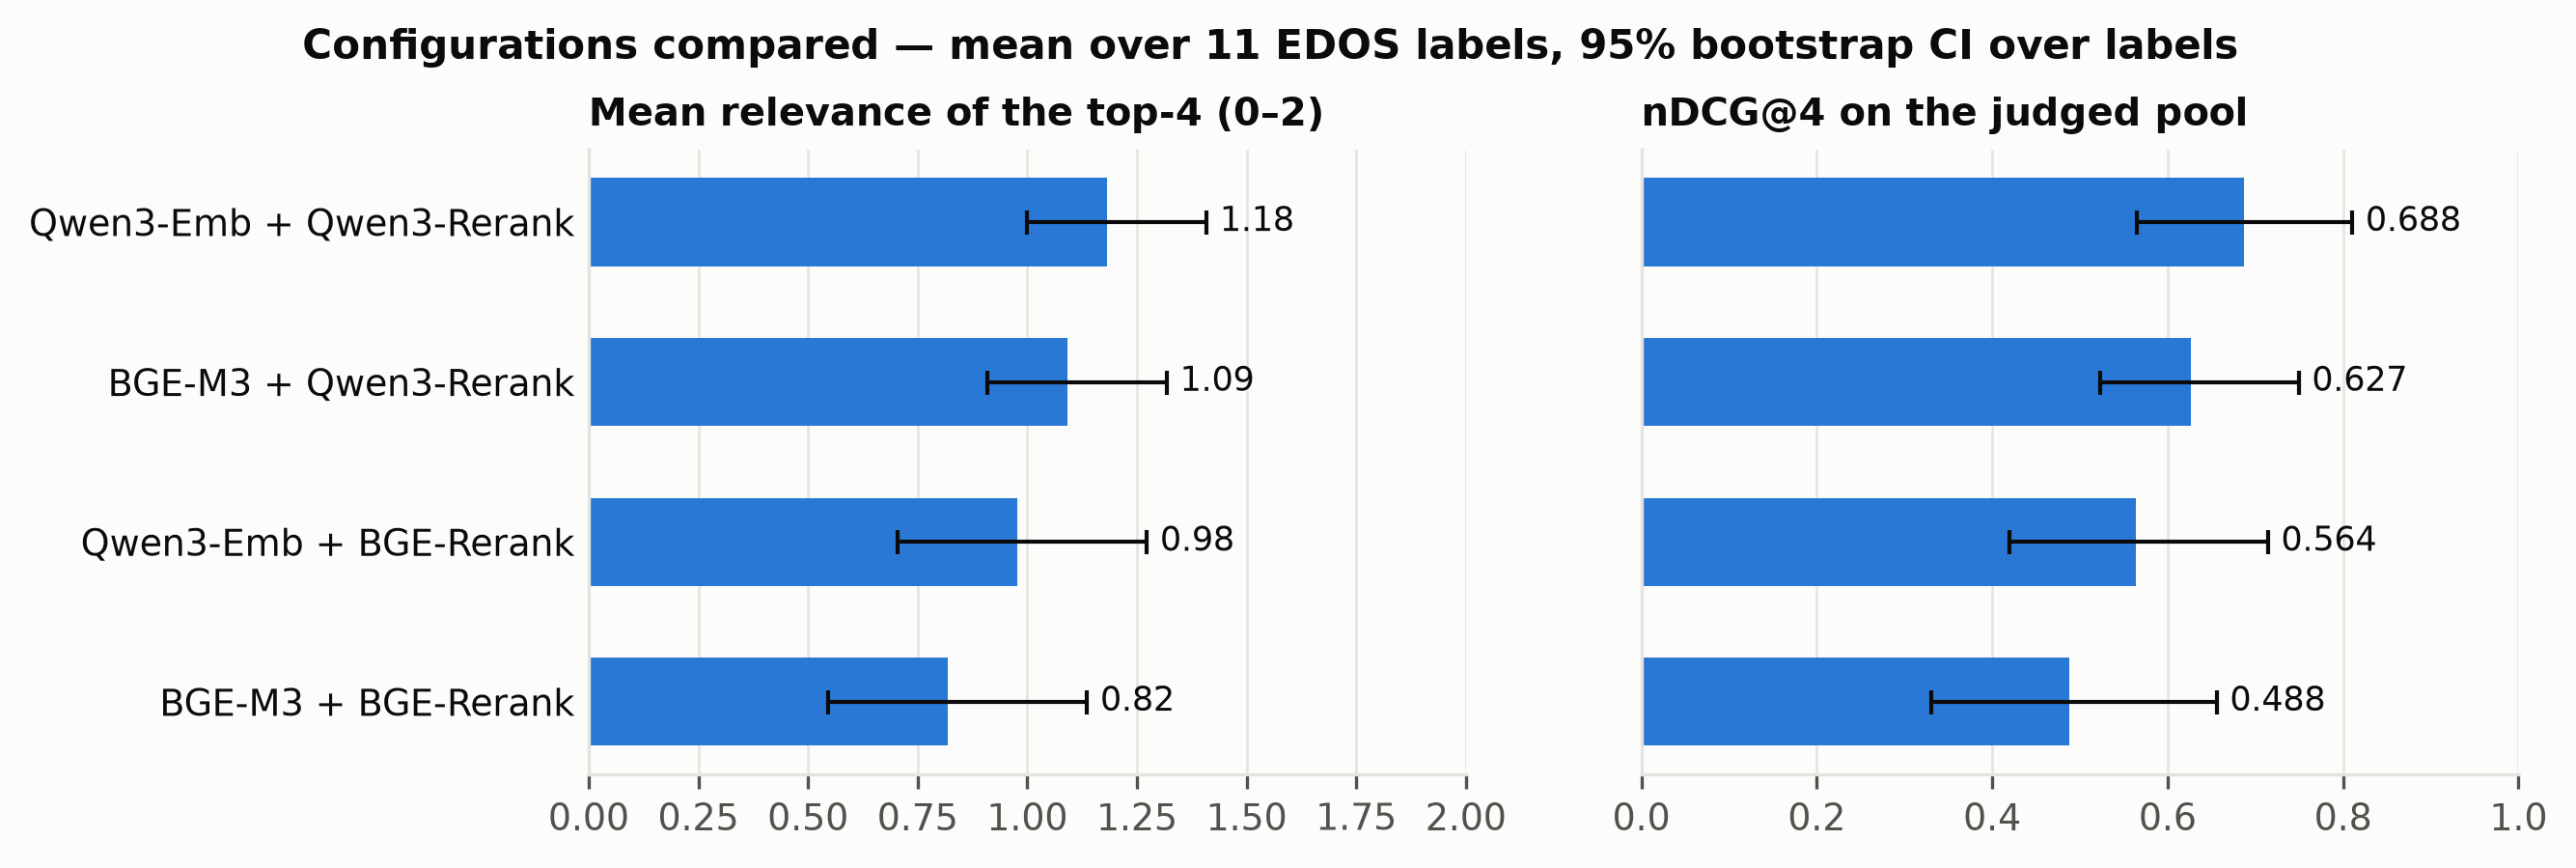

In [33]:
pr.figure_model_ranking(summary)
display(Image(pr.FIGURES / "1_model_ranking.png", width=900))

## 5. Embedder × reranker

Le quattro configurazioni sono un disegno 2 × 2. Linee quasi parallele = l'effetto dell'embedder è
simile con entrambi i reranker, cioè i due effetti si sommano.

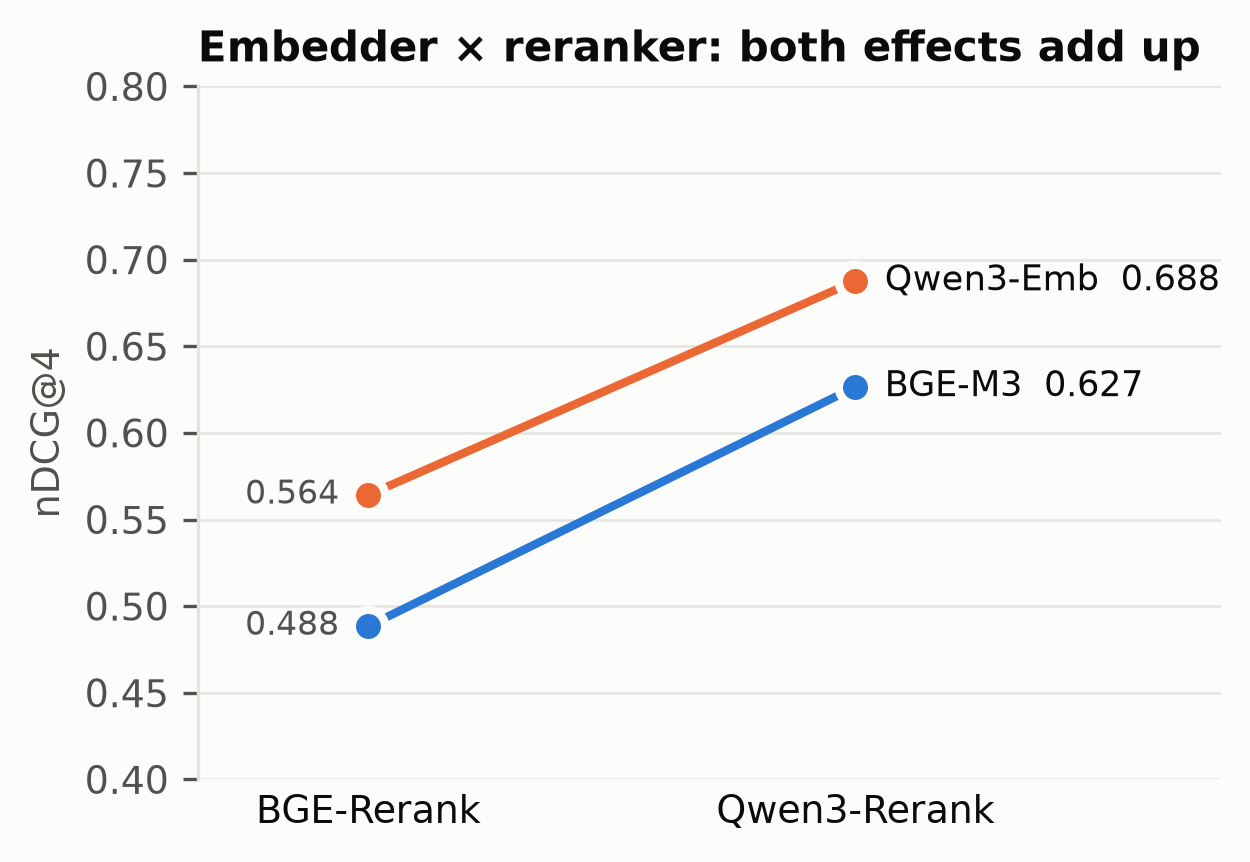

In [34]:
pr.figure_factorial(summary)
display(Image(pr.FIGURES / "3_embedder_x_reranker.png", width=450))

## 6. Pattern per etichetta

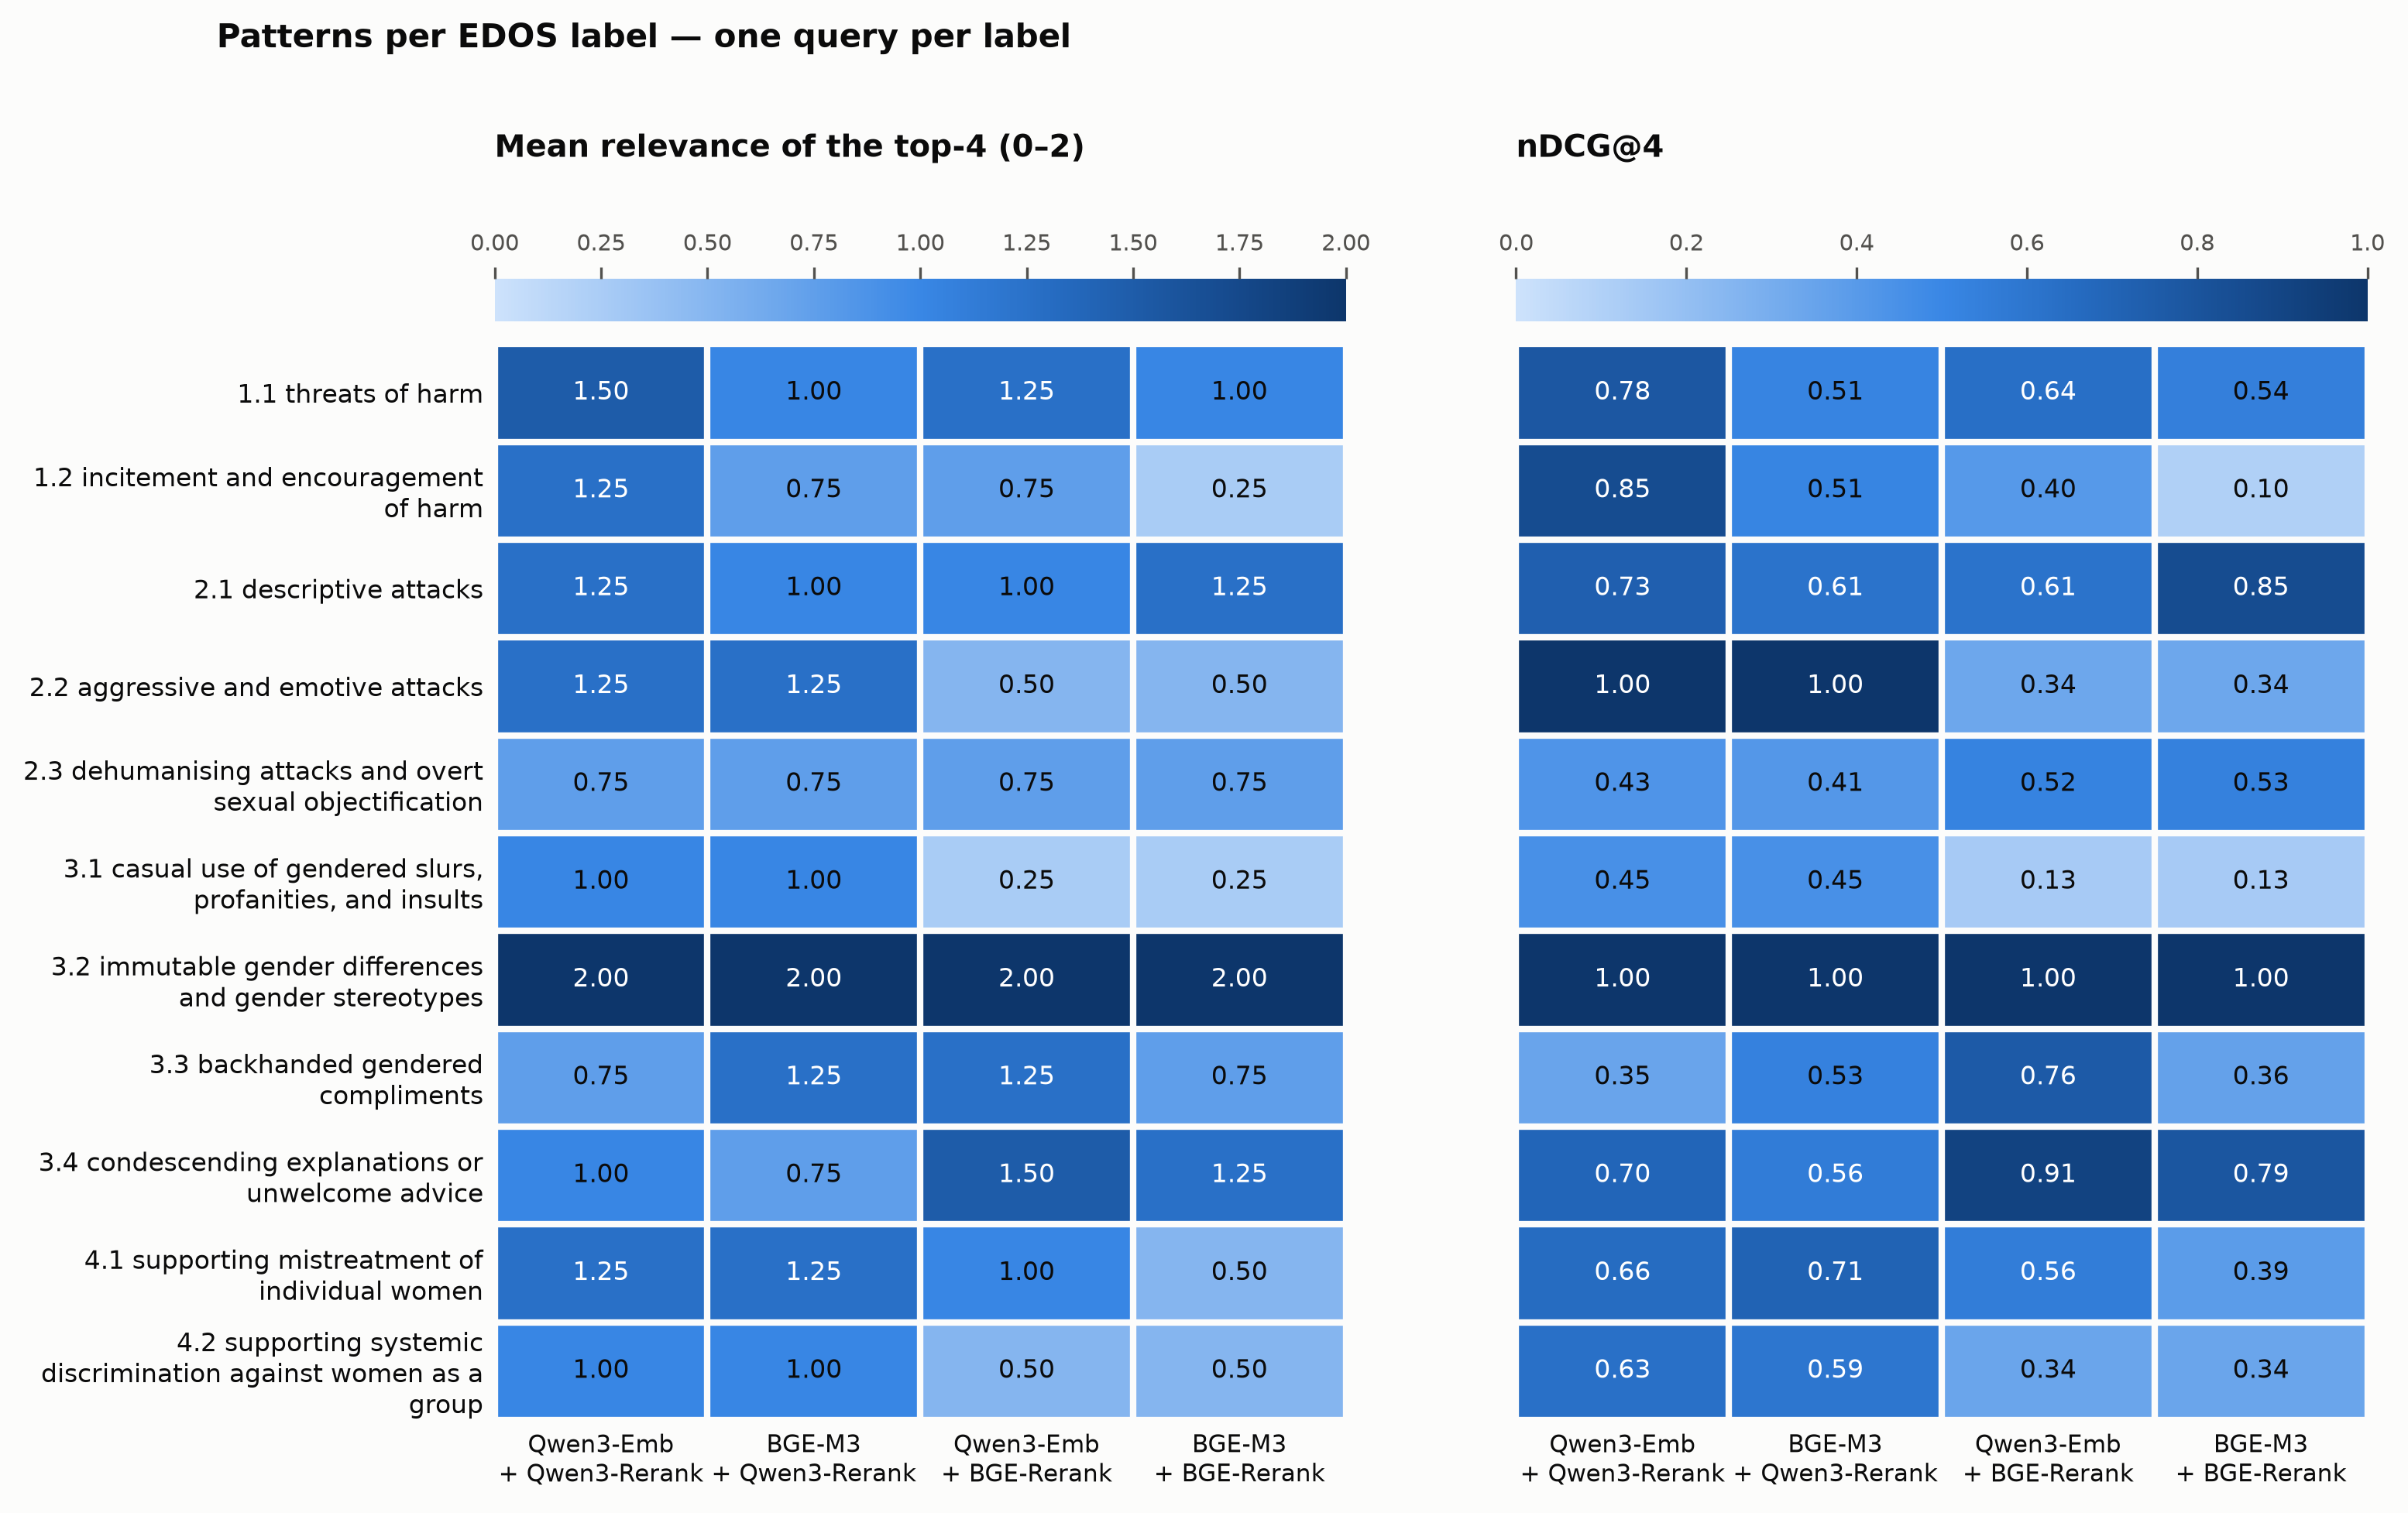

In [35]:
pr.figure_heatmap(per_label)
display(Image(pr.FIGURES / "4_patterns_per_label.png", width=1000))

In [36]:
per_label.pivot(index="label", columns="configuration", values="nDCG@4")[pr.ORDER].rename(columns=pr.NAMES)

configuration,Qwen3-Emb + Qwen3-Rerank,BGE-M3 + Qwen3-Rerank,Qwen3-Emb + BGE-Rerank,BGE-M3 + BGE-Rerank
label,,,,
1.1 threats of harm,0.779,0.514,0.637,0.539
1.2 incitement and encouragement of harm,0.850,0.508,0.404,0.103
2.1 descriptive attacks,0.730,0.611,0.611,0.850
2.2 aggressive and emotive attacks,1.000,1.000,0.335,0.335
2.3 dehumanising attacks and overt sexual objectification,0.426,0.411,0.518,0.533
"3.1 casual use of gendered slurs, profanities, and insults",0.452,0.452,0.134,0.134
3.2 immutable gender differences and gender stereotypes,1.000,1.000,1.000,1.000
3.3 backhanded gendered compliments,0.348,0.531,0.759,0.361
3.4 condescending explanations or unwelcome advice,0.695,0.561,0.908,0.787


## Sintesi

- **Accordo**: prima della discussione è basso (α ordinale ≈ 0,23, sotto 0,667); i disaccordi 0 contro 2
  sono stati discussi e risolti quasi sempre con il livello intermedio.
- **Retrieval**: Qwen3-Embedding-8B + Qwen3-Reranker-8B ha la rilevanza media e l'nDCG@4 più alti;
  sia il reranker Qwen sia l'embedder Qwen migliorano i risultati, e i due effetti si sommano.
- **Incertezza**: con 11 etichette e 81 item giudicati da una sola annotatrice gli intervalli di
  confidenza sono ampi e si sovrappongono.

I grafici sono rigenerati dal notebook e salvati (PNG e PDF) in `results/evaluation/figures/`.